# 01 – Exploration des données

Objectif : vérifier les données téléchargées et se faire une première idée des actions : rendements, volatilité, drawdowns et corrélations.

Avant de lancer ce notebook : `python src/ingest.py` (ou `--demo` sans internet).

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

from analytics import (daily_returns, drawdown, load_prices, summary_table)

plt.rcParams['figure.figsize'] = (11, 5)
pd.options.display.float_format = '{:.3f}'.format

## 1. Charger les prix

In [3]:
prices = load_prices(ROOT / 'data' / 'market.duckdb')
print(f'{prices.shape[1]} tickers, du {prices.index.min():%d/%m/%Y} au {prices.index.max():%d/%m/%Y}')
prices.tail()

50 tickers, du 01/01/2015 au 09/11/2026


ticker,AAPL,ABBV,ABT,ADBE,AMGN,AMZN,AVGO,BAC,BRK-B,CAT,...,T,TMO,TXN,UNH,UNP,UPS,V,VZ,WMT,XOM
date,,,,,,,,,,,,,,,,,,,,,
2026-11-03,73.462,258.697,181.084,108.972,217.872,28.122,181.942,164.857,400.717,225.500,...,576.827,270.317,126.104,207.132,44.569,390.090,41.951,107.558,44.050,261.364
2026-11-04,72.624,260.838,183.942,106.498,207.032,29.351,175.611,164.063,404.945,220.384,...,578.294,275.597,124.796,206.697,45.225,393.097,42.471,111.040,45.794,251.000
2026-11-05,73.866,259.173,182.927,105.267,205.549,29.522,179.271,165.158,413.075,225.066,...,562.587,274.378,125.850,206.586,45.643,384.993,40.699,108.903,45.962,262.881
2026-11-06,72.868,268.645,188.427,105.023,204.211,30.122,185.631,164.839,412.796,222.263,...,557.903,269.013,126.185,201.276,44.663,385.556,37.247,109.919,45.311,277.233
2026-11-09,75.292,271.376,187.260,105.346,200.098,30.594,183.245,162.848,415.364,221.414,...,560.939,275.188,125.955,201.401,45.821,391.952,37.659,108.305,44.486,276.024


## 2. Contrôle qualité

Valeurs manquantes par ticker (les entreprises entrées en bourse après 2015 en ont au début).

In [4]:
prices.isna().sum().sort_values(ascending=False).head(10)

ticker
AAPL    0
PFE     0
MCD     0
META    0
MRK     0
MS      0
MSFT    0
NFLX    0
NKE     0
NVDA    0
dtype: int64

## 3. Performance cumulée

Toutes les actions ramenées à 1 au départ pour les comparer.

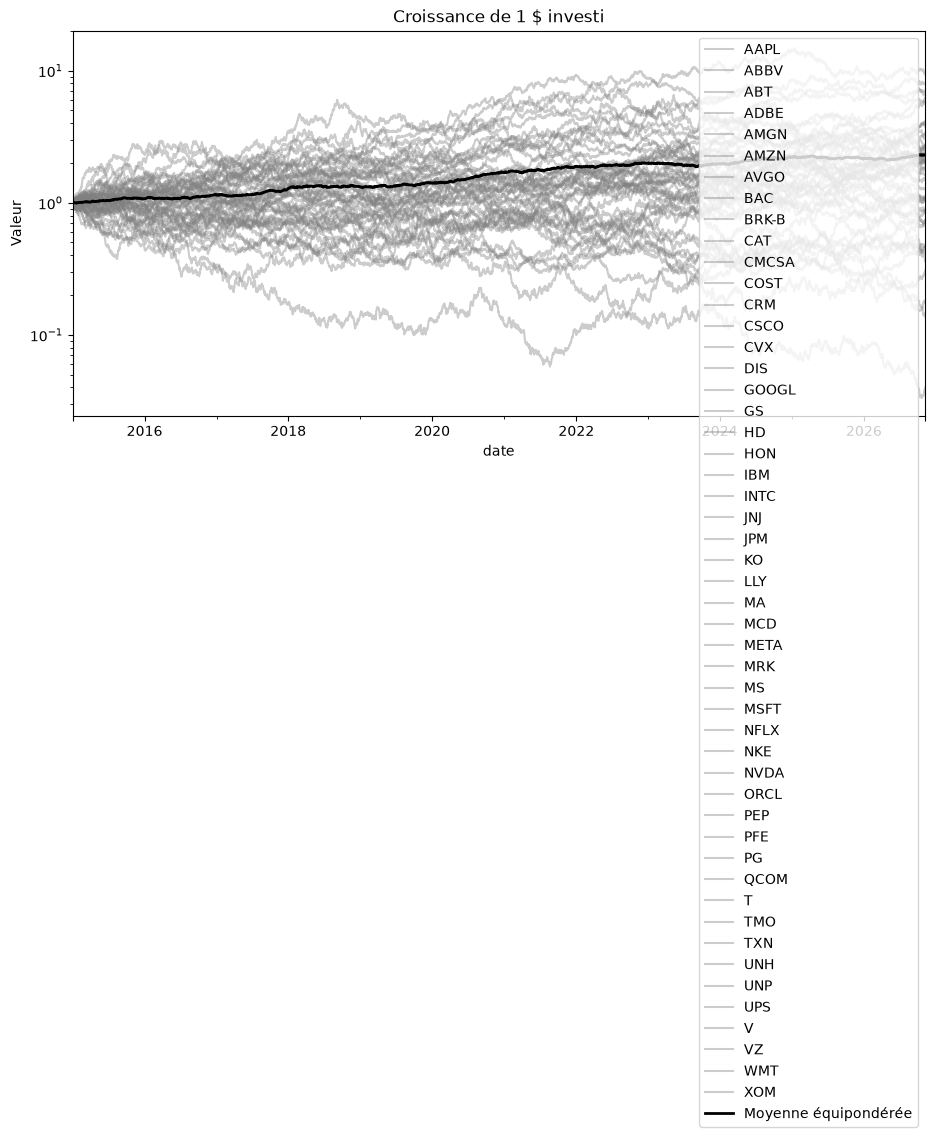

In [5]:
normalized = prices / prices.bfill().iloc[0]
ax = normalized.plot(legend=False, alpha=0.4, color='grey')
normalized.mean(axis=1).plot(ax=ax, color='black', linewidth=2, label='Moyenne équipondérée')
ax.set(title='Croissance de 1 $ investi', ylabel='Valeur', yscale='log')
ax.legend();

## 4. Tableau récapitulatif

Rendement annualisé, volatilité, Sharpe et pire perte de chaque action.

In [6]:
returns = daily_returns(prices)
stats = summary_table(returns)
stats

,rendement_annuel,volatilite_annuelle,sharpe,max_drawdown
ticker,,,,
NVDA,0.172,0.197,0.906,-0.354
LLY,0.200,0.247,0.862,-0.444
META,0.169,0.206,0.862,-0.439
DIS,0.184,0.230,0.852,-0.295
CSCO,0.115,0.157,0.770,-0.265
T,0.151,0.214,0.765,-0.351
BRK-B,0.123,0.176,0.746,-0.305
MA,0.161,0.259,0.704,-0.498
NKE,0.103,0.189,0.612,-0.321


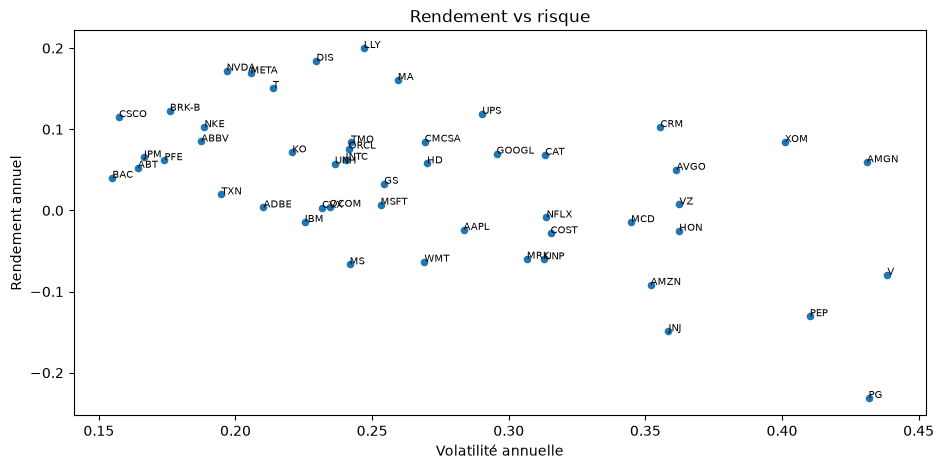

In [7]:
ax = stats.plot.scatter(x='volatilite_annuelle', y='rendement_annuel')
for t, row in stats.iterrows():
    ax.annotate(t, (row['volatilite_annuelle'], row['rendement_annuel']), fontsize=7)
ax.set(title='Rendement vs risque', xlabel='Volatilité annuelle', ylabel='Rendement annuel');

## 5. Drawdown du portefeuille équipondéré

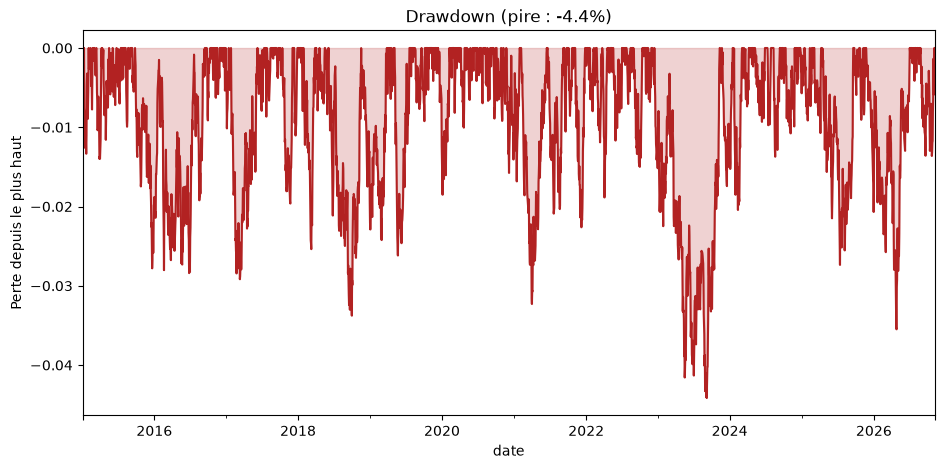

In [8]:
portfolio = returns.mean(axis=1)
dd = drawdown(portfolio)
ax = dd.plot(color='firebrick')
ax.fill_between(dd.index, dd, 0, color='firebrick', alpha=0.2)
ax.set(title=f'Drawdown (pire : {dd.min():.1%})', ylabel='Perte depuis le plus haut');

## 6. Corrélations

Des actions très corrélées apportent peu de diversification.

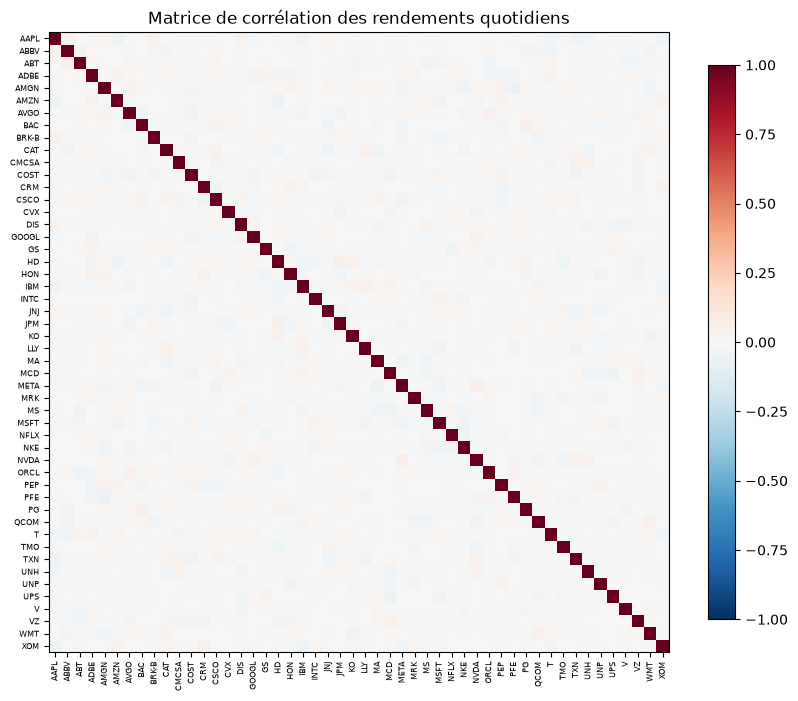

In [9]:
corr = returns.corr()
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=6)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Matrice de corrélation des rendements quotidiens');

In [10]:
print(f"Corrélation moyenne entre actions : {corr.where(~(corr == 1)).stack().mean():.2f}")

Corrélation moyenne entre actions : 0.00


## À noter pour la suite

- Ce que tu observes : quelles actions dominent ? Les corrélations augmentent-elles en crise ?
- Prochaine étape : modèles dbt (rendements, volatilité glissante, momentum 12-1) et tests de qualité.
- Garde en tête le biais du survivant : ces 50 actions sont les gagnantes d'aujourd'hui.